## 1. Car Price Prediction Project

We will use this dataset from Kaggle: [https://www.kaggle.com/datasets/CooperUnion/cardataset](https://www.kaggle.com/datasets/CooperUnion/cardataset).

The dataset can be found locally in this repo next to this ipynb as `data.csv`.

What we want to predict is the `MSRP` (Manufacturer's Suggested Retail Price).

The project plan:
- Get the data, **Prepare the data**, and do **EDA (Exploratory Data Analysis)**.
- Use **Linear Regression** for predicting the price.
- Understand the internals of Linear Regression
- **Evaluating the model** with **RMSE (Root Mean Squared Error)** which tells us about the quality of a model.
- **Feature Engineering**: the process of creating new features or new characteristics.
- **Regularization** to solve some numerical stability problems.
- Using the model.

## 2. Data Preparation

In [2]:
import pandas as pd
import numpy as np

In [3]:
!wget -nc https://raw.githubusercontent.com/k-candidate/mlbookcamp-code/refs/heads/master/chapter-02-car-price/data.csv

File ‘data.csv’ already there; not retrieving.



In [4]:
df = pd.read_csv("data.csv")

In [5]:
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [6]:
df.columns

Index(['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP',
       'Engine Cylinders', 'Transmission Type', 'Driven_Wheels',
       'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style',
       'highway MPG', 'city mpg', 'Popularity', 'MSRP'],
      dtype='str')

We see that there are inconsistencies in the column names: some with spaces and some with underscores, some with capital letters ...
So let's do a bit of "cleaning" by making it consistent: lowercases and underscores.

In [7]:
df.columns = df.columns.str.lower().str.replace(" ", "_")
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

We also have the same problem with the values. But we can't run the same command on it because there are different data types in the values:

In [8]:
df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

So the "text" ones that matter to us are of the type `str`. In older versions of pandas (`<3.0`), the `str` type used to be called `object`.

In [9]:
df.dtypes[df.dtypes == "str"]

make                 str
model                str
engine_fuel_type     str
transmission_type    str
driven_wheels        str
market_category      str
vehicle_size         str
vehicle_style        str
dtype: object

In this output table immediately above, the left side is the "INDEX" and the right side is the "VALUES.
What we care about is the INDEX.

In [10]:
strings = list(df.dtypes[df.dtypes == "str"].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [11]:
for col in strings:
    df[col] = df[col].str.lower().str.replace(" ", "_")

In [12]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


## 3. EDA (Exploratory Data Analysis)

Let's look at the different columns and try to understand what data is there.

In [13]:
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

In [14]:
df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [15]:
df

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,46120
11910,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,56670
11911,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50620
11912,acura,zdx,2013,premium_unleaded_(recommended),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50920


In [16]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

make
<StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
48

model
<StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
914

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
<StringArray>
[   'premium_unleaded_(required)',               'regular_unleaded',
 'premium_unleaded_(recommended)',       'flex-fuel_(unleaded/e85)',
                         'diesel']
Length: 5, dtype: str
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
<StringArray>
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
Length: 5, dtype: str
5

driven_wheels
<StringArray>
['rear_wheel_drive', 'front_wheel_drive', 'all_wheel_drive',
 'four_wheel_drive']
Length: 4, dtype: str
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
<StringArray>
['factory_tuner,luxury,high-performance',
                    'luxury,performance',
               'luxury,high-pe

In [17]:
# Look at the last column: MSRP
df

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,46120
11910,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,56670
11911,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50620
11912,acura,zdx,2013,premium_unleaded_(recommended),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50920


In [18]:
# We want to visualize the distribution of the target variable (MSRP). Let's use a histogram for that.
import matplotlib.pyplot as plt
import seaborn as sns
# matplotlib is like the low level library, and seaborn is a high level library that makes it easier to create plots.

# This magic command is only available in Jupyter notebooks. It makes the plots appear in the notebook itself.
%matplotlib inline

<Axes: xlabel='msrp', ylabel='Count'>

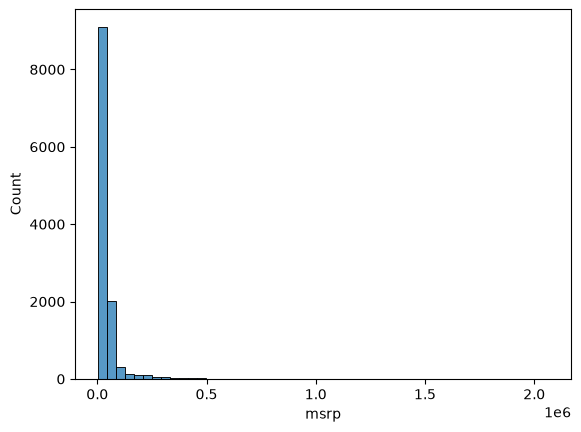

In [19]:
sns.histplot(df.msrp, bins=50)
# bins is the number of bars in the histogram.
# The more bins, the more detailed the histogram will be.
# The less bins, the more general the histogram will be.

1e6 is scientific notation, and it means 10 to the 6th power, or 1 million.
So we see that most of the prices are "pretty cheap" (the left side of the chart), and very few cars that are super expensive.
This kind of distribution is called a **LONG-TAIL DISTRIBUTION**

<Axes: xlabel='msrp', ylabel='Count'>

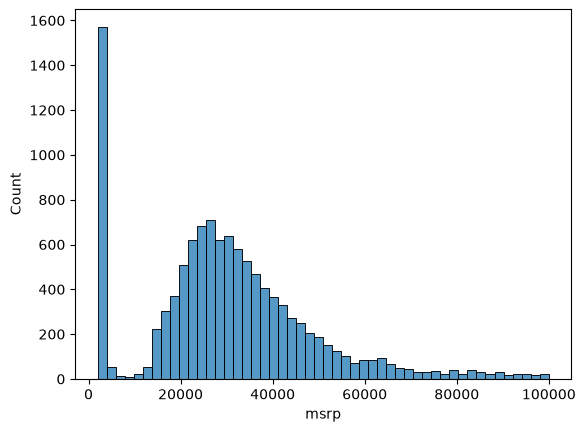

In [20]:
# So we need to zoom in on the left side of the histogram to see the distribution of the majority of the data.
# Let's look for example at the distribution of the MSRP values that are less than 100,000.
sns.histplot(df.msrp[df.msrp < 100000], bins=50)

There is a strange peak of cars that cost 1,000, probably the minimal price possible to put on the platform that gathered this data, which is why a bunch of cars cost exactly that.  
Then the number of cars slowly grows up to around 25,000. About 700 cars cost that much. And after that it goes down as the price grows.  
Except for that peak at 1,000, this is a pretty reasonable distribution to expect for prices.

### Removing the long tail with a logarithm

While this long-tail distribution is not unexpected for prices in general (not many people can afford high prices but there a few, and the majority of transactions are in low prices), it is not really good for machine learning: the long tail will mess things up for the model.  
We want to get rid of it, and the usual trick is to apply the **logarithm** to the price.

The logarithm compresses large values. For large numbers, the value of the logarithm is not that large: going from 10 to 1,000 is a big jump, but the increase between their logarithms is not that high. So the logarithm takes very high values and makes them lower.

There is **one problem with the plain logarithm**: **the logarithm of zero doesn't exist**. If there is a zero in the data, numpy complains: it returns negative infinity and prints a warning.

In [21]:
np.log(0)

/tmp/ipykernel_74176/2933082444.py:1: RuntimeWarning: divide by zero encountered in log
  np.log(0)


np.float64(-inf)

In [22]:
np.log([0, 1, 10, 1000, 100000])

/tmp/ipykernel_74176/1040805571.py:1: RuntimeWarning: divide by zero encountered in log
  np.log([0, 1, 10, 1000, 100000])


array([       -inf,  0.        ,  2.30258509,  6.90775528, 11.51292546])

In our case prices are always 1,000 or more, so this can't happen. Still, it's pretty common to add one to all values before taking the logarithm, just to be safe. NumPy has a shortcut for exactly this: `log1p`, where "1p" stands for "plus one". It adds one to every value and then takes the logarithm:

In [23]:
np.log([0+1, 1+1, 10+1, 1000+1, 100000+1])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [24]:
np.log1p([0, 1, 10, 1000, 100000])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [25]:
price_logs = np.log1p(df.msrp)

<Axes: xlabel='msrp', ylabel='Count'>

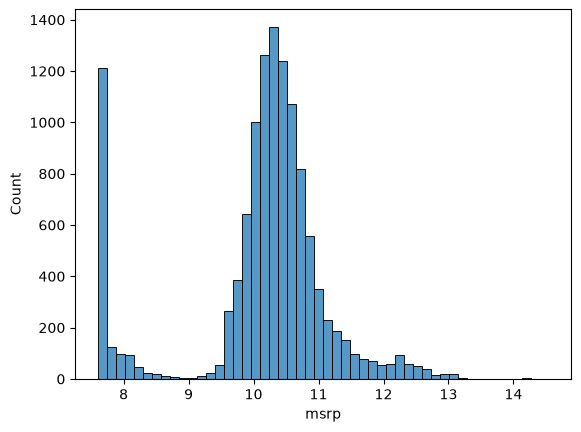

In [26]:
# histogram of the log-transformed prices
sns.histplot(price_logs, bins=50)

The tail is gone. All the large prices collapsed into a small area on the right, and the cars for usual consumers are still concentrated around the center. The shape now resembles a bell curve: a clear center of the distribution that goes down on both the left and the right side. This is called a normal distribution. We still have that weird peak at 1,000, but apart from it, it looks close to normal.

This situation is ideal for models: **models do much better when the target variable looks like a normal distribution than with long-tail ones**. That is why we typically want to get rid of long tails, and applying the logarithm to the price, like we just did, is one way of doing it.

### Missing values

One more thing before we finish: missing values. Some values in the dataset were not recorded. When pandas doesn't have a value, it shows it as NaN (not a number). We saw this when looking at the data: some cars have NaN in the number of doors column.

To count how many missing values there are, we use `isnull()`: for every cell it says whether the value in this cell is missing or not. In this form it is not super useful, so we follow it with `sum()`, which sums across every column and tells us the number of missing values in each:

In [27]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

For quite a few cars we don't know the fuel type, the market category, the horsepower or the number of cylinders.

**We need to keep this in mind: before training the model, we will need to do something with these missing values.**

## 4. Setting up the Validation Framework

Now we set up the **validation framework**: we **split the data into train, validation and test parts**, and prepare the target variable for each part.

```mermaid
graph LR
    subgraph Dataset Split
        A[Full Dataset] --> B[Train 60%]
        A --> C[Validation 20%]
        A --> D[Test 20%]
    end
    
    style B fill:#f9f,stroke:#333,stroke-width:2px
    style C fill:#bbf,stroke:#333,stroke-width:2px
    style D fill:#bfb,stroke:#333,stroke-width:2px
```

The mermaid diagram above will show if you are on the web browser, but not on vscode with the jupyter extension.  
It's a known bug: [https://github.com/microsoft/vscode-jupyter/issues/17528](https://github.com/microsoft/vscode-jupyter/issues/17528).  
So I am showing the alternative image:  
![Validation Framework](https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/02-regression/images/04-validation-framework-01-train-val-test-split-crisp.jpg)

We will do a 60/20/20 split.  
We want a whole number of records, not a fraction. so we cut the fraction off with `int()`.

In [29]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test
# Ideally we would write `n_train = int(n * 0.6)` as well, but because of rounding, the three parts may stop adding up to `n`.

n, n_val, n_test, n_train, n_val + n_test + n_train

(11914, 2382, 2382, 7150, 11914)

### Taking a part of the dataframe with iloc

Now we know the sizes, we need to split the dataset using `iloc`. We usually give it a list of indices, but it also accepts ranges.  
e.g., `df.iloc[:10]` takes record 0 to 9; `df.iloc[10:20]` takes records 10 to 19; `df.iloc[10:] takes everything from 10 to the end.

In [31]:
df_val = df.iloc[:n_val]
df_test = df.iloc[n_val:n_val+n_test]
df_train = df.iloc[n_val+n_test:]

There is a problem here, though: the split is sequential. In our dataset the cars are ordered by make, so validation now contains all the BMWs at the beginning and all the Porsches at the end, and there are no BMWs in train at all.

There is some order in this dataset, and we need to break it. **In general it is always a good idea to shuffle the data: if there is some accidental order in it, we want to make sure it does not affect the split.**

### Shuffling the records

Here is the idea. In iloc we can pass an arbitrary sequence of numbers, and it will return the rows in that order. So we can take the numbers from 0 to n-1, reshuffle them, and then take the first 20% of the shuffled numbers for validation, the next 20% for test, and the rest for train

To generate the sequence of numbers we use `np.arange` from NumPy, and to shuffle it we use `np.random.shuffle`:

In [32]:
idx = np.arange(n)
np.random.shuffle(idx)

In [34]:
# Now we index the dataframe with the shuffled numbers instead of the sequential ranges:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]
# We take the first n_train numbers for train, the next n_val numbers for validation, and everything that is left for test

There is **one more problem with this code: it is not reproducible.** When you run it on your computer, you will get different records, because your shuffling order is different from mine.

**To make the results reproducible, we set a random seed before shuffling.**

In [35]:
np.random.seed(2)

idx = np.arange(n)
np.random.shuffle(idx)

### Resetting the index

In [36]:
# Let's check the lengths of the three dataframes:
len(df_train), len(df_val), len(df_test)

(7150, 2382, 2382)

In [37]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
3253,cadillac,cts,2015,premium_unleaded_(recommended),272.0,4.0,automatic,rear_wheel_drive,4.0,"luxury,performance",large,sedan,30,20,1624,55670
2681,mercedes-benz,cl-class,2013,premium_unleaded_(required),429.0,8.0,automatic,all_wheel_drive,2.0,"luxury,high-performance",large,coupe,24,15,617,115300
3411,mazda,cx-9,2015,regular_unleaded,273.0,6.0,automatic,front_wheel_drive,4.0,crossover,large,4dr_suv,24,17,586,29985
3577,land_rover,discovery_series_ii,2001,premium_unleaded_(required),188.0,8.0,automatic,four_wheel_drive,4.0,luxury,midsize,4dr_suv,16,12,258,33350
1607,toyota,avalon,2017,regular_unleaded,268.0,6.0,automatic,front_wheel_drive,4.0,NaN,midsize,sedan,30,21,2031,33250


Looking at `df_train`, we see that the index now contains the original row numbers, in random order.  
Sometimes it is inconvenient: we don't really need to know what the original index of each record was.  
So we reset the index and reassign the result back to the dataframe.   
We pass `drop=True` because we don't need the old index as a column:

In [38]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [39]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,cadillac,cts,2015,premium_unleaded_(recommended),272.0,4.0,automatic,rear_wheel_drive,4.0,"luxury,performance",large,sedan,30,20,1624,55670
1,mercedes-benz,cl-class,2013,premium_unleaded_(required),429.0,8.0,automatic,all_wheel_drive,2.0,"luxury,high-performance",large,coupe,24,15,617,115300
2,mazda,cx-9,2015,regular_unleaded,273.0,6.0,automatic,front_wheel_drive,4.0,crossover,large,4dr_suv,24,17,586,29985
3,land_rover,discovery_series_ii,2001,premium_unleaded_(required),188.0,8.0,automatic,four_wheel_drive,4.0,luxury,midsize,4dr_suv,16,12,258,33350
4,toyota,avalon,2017,regular_unleaded,268.0,6.0,automatic,front_wheel_drive,4.0,NaN,midsize,sedan,30,21,2031,33250


### Preparing and removing msrp

The dataframes will be used to make the feature matrix $X$.  
The target $y$ comes from the `msrp` column, and we already know that we need to apply the `log1p` transformation to it because of the long tail in its distribution.  
Instead of keeping a pandas series, we immediately take its values with `.values` to get a NumPy array. We don't need the indexes and other pandas things for $y$.

In [40]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

The last thing we need to do is remove `msrp` from the dataframes, for which we use the `del` operator:

In [41]:
del df_train["msrp"]
del df_val["msrp"]
del df_test["msrp"]

We delete it because we might accidentally use it.  
If the price gets into the features, we will use the price to predict the price. And of course the model will be perfect. Then we might spend time figuring out what is wrong.  
**After splitting the data always take the target out into a separate variable and delete it from the dataframe completely.**

In [42]:
len(y_train)

7150

## 5. Linear Regression

Remember from the introduction: there is regression, there is classification and there is ranking.  
Regression means predicting numbers, and the output of this model is a number - in our case, the price of a car.

$$g(X) \approx y$$

Here $g$ is our model, $X$ is the feature matrix and $y$ is our target (the price). The model $g$ will be linear regression.

Before we go to the matrix form, let's simplify and look at one observation instead of the entire feature matrix. One observation is one car.

A car can be a row in our feature matrix, so we can think of it as a vector with $n$ elements: the first feature is $x_{i1}$, then $x_{i2}$, and so on until $x_{in}$.  
We want a function that takes all these features and produces something close to the price:

$$
\begin{aligned}
    g(x_i) &\approx y_i \\
    x_i &= (x_{i1}, x_{i2}, \dots, x_{in}) \\
    g(x_{i1}, x_{i2}, \dots, x_{in}) &\approx y_i
\end{aligned}
$$

Let's take an example from the training dataset. Remember, we don't look at validation or test here, only at training.  
Let's take row number 10:

In [43]:
df_train.iloc[10]

make                              ford
model                     five_hundred
year                              2005
engine_fuel_type      regular_unleaded
engine_hp                        203.0
engine_cylinders                   6.0
transmission_type            automatic
driven_wheels        front_wheel_drive
number_of_doors                    4.0
market_category                    NaN
vehicle_size                     large
vehicle_style                    sedan
highway_mpg                         26
city_mpg                            19
popularity                        5657
Name: 10, dtype: object

It is a Ford Five Hundred manufactured in 2005 among many other characteristics.  
We just take three of them: engine horsepower, city miles per gallon, and popularity.  
So, for this car the feature vector is:

In [46]:
xi = [203, 19, 5657]

Here $i$ is 10, and the features are engine horsepower (203), miles per gallon in the city (19) and popularity (5657).  
Popularity is the number of times people mention this car on Twitter.  
Now we need a function that takes this `xi` and produces a prediction for this car.

### The Linear Regression Formula

We need to combine these values in a way that gives us something close to the price.  
The formula for linear regression is:

$$g(x_i) = w_0 + w_1 \cdot x_{i1} + w_2 \cdot x_{i2} + w_3 \cdot x_{i3}$$

First we have the **bias term** $\mathbf{w_0}$: this is **the prediction we make without knowing anything about the car**.

But we do know something, so **each feature is multiplied by its weight**: horsepower gets weight $w_1$, miles per gallon gets $w_2$, popularity gets $w_3$.

The part with the features is a sum, so we can write the formula more compactly.  
Because we already use $\mathbf{i}$ for **the car**, we use $\mathbf{j}$ for **the features**, and it goes from 1 to n (in our example, 3):

$$g(x_i) = w_0 + \sum_{j=1}^{n} w_j \cdot x_{ij}$$

### Implementing it in Python

In [48]:
xi = [203, 19, 5657]

# We are just making up w0, w1, w2, and w3 for the sake of this example.
# In practice, we would learn these weights from the training data using a machine learning algorithm.
w0 = 7.17
w = [0.01, 0.04, 0.002]

def linear_regression(xi, w0, w):
    """
    xi: list of features for a single data point
    w0: bias term
    w: list of weights for each feature
    """
    n = len(xi)

    pred = w0

    for j in range(n):
        pred += w[j] * xi[j]

    return pred

linear_regression(xi, w0, w)

21.274

So what's the meaning of the numbers?
- **Bias term**, 7.17. This is **what we predict for an average car if we don't know anything about it**.
- The car has 203 horsepower. Each horsepower adds 0.01 to the prediction: if the car had only one horsepower, the price would be higher by 0.01, and for 100 horsepower it's higher by 1. The more horsepower the engine has, the more expensive the car becomes. That's logical.
- The next feature is miles per gallon in the city, with weight 0.04. The more fuel the car consumes in the city, the more expensive it is. This can make sense: cars that consume more fuel are probably fancier.
- The last one is popularity, the number of mentions on Twitter, with a pretty low weight of 0.002. It doesn't seem to affect the price much: a lot of people would need to mention a car for this term to matter.

### From log price back to dollars

The prediction 21.274 is NOT the price in dollars.  
Remember that **we applied the `log1p` transformation to `y` because of the long tail in the price distribution**, so **our model predicts the logarithm of the price**. To undo the logarithm we need the exponent. Remember that we also added 1.  
In NumPy there is a function for that:

In [51]:
np.exp(21.274) -1

np.float64(1734525974.417661)

In [49]:
np.expm1(21.274)

np.float64(1734525974.417661)

In [50]:
np.log1p(1734525974.417661)

np.float64(21.274)

So our prediction for the price of this car is about 1,734,525,974 dollars. You get the idea.

That's linear regression for one car: we implemented the formula on a small feature vector of size three.

In the next section we generalize it to all the cars at once: the vector form.

## 6. Linear Regression: Vector Form

We implemented linear regression for a single car.  
Now we generalize it: first to a dot product for one car, then to a matrix-vector multiplication that produces predictions for all the cars in the dataset at once.

### The dot product

$g$ is our model (linear regression), $X$ is the feature matrix (the training data) and $y$ is the target, the price:

$$g(X) \approx y$$

Let's again write the formula for a single car first. We have the bias term $w_0$ and then a sum that goes from $1$ to $n$, where we multiply each feature $x_{ij}$ with its weight $w_j$:

$$g(x_i) = w_0 + \sum_{j=1}^{n} x_{ij} \cdot w_j$$

If we look at the sum, we can see that it is nothing else but a dot product (a vector-vector multiplication). We talked about dot products in the introduction, and using that notation we can rewrite the formula slightly differently: we take the vector $x_i$, transpose it, and multiply it with the vector of weights:

$$g(x_i) = w_0 + x_i^T w$$

This notation is more compact, so let's implement it.  
We already have the `linear_regression` function; let's first extract the sum into a function of its own. It is the same vector-vector multiplication we implemented before: start the result at zero and, for each element, multiply the pair and add it to the result:

In [52]:
def dot(xi, w):
    n = len(xi)

    res = 0.0

    for j in range(n):
        res = res + xi[j] * w[j]

    return res

Now the linear regression function becomes short: it just adds the bias term to the dot product between the features and the weights.

In [53]:
def linear_regression(xi):
    return w0 + dot(xi, w)

### The fictional feature

We can make it even shorter. The bias term $w_0$ is kind of hanging out there all alone, without a feature. Let's bring it into the dot product: we imagine that there is one extra feature of our car, $x_{i0}$, and this feature is always 1.

Then the vector of weights becomes $w_0$, $w_1$, $w_2$ and so on up to wn. It is an $n+1$ dimensional vector now. And the vector of features becomes $x_{i0}$, $x_{i1}$, $x_{i2}$ and so on, where $x_{i0}$ is $1$:

$$
\begin{aligned}
W &= \left[ \begin{matrix} w_0 & \overbrace{\begin{matrix} w_1 & w_2 & \dots & w_n \end{matrix}} \end{matrix} \right] \text{ } n+1 \text{ dim} \\
X_i &= \begin{bmatrix} 1 & X_{i1} & X_{i2} & \dots & X_{in} \end{bmatrix} \\
W^T X_i &= X_i^T W
\end{aligned}
$$




Why does this work? When we do the dot product, $w_0$ gets multiplied by $1$, so it simply stays there, and the rest is the same dot product as before. The result is equivalent to what we had, which means we can use the dot product notation for the entire linear regression.

In code, in Python, adding two lists with `+` creates a new list and prepends the first one at the beginning, which is exactly what we need:

In [56]:
w_new = [w0] + w
w_new

[7.17, 0.01, 0.04, 0.002]

In [57]:
# We do the same with the features: prepend 1 to xi, and then take the dot product of the two new vectors:
def linear_regression(xi):
    xi_new = [1] + xi
    return dot(xi_new, w_new)

linear_regression(xi)

21.274

And it is the same 21.274 we got earlier in section 5.

### Linear Regression for All Cars

Now let's go back to thinking about all the examples, not just one. We have the matrix $X$. Because of the fictional feature, each row of this matrix starts with $1$, followed by the features of that car: row one is car one, row two is car two, and so on until row m.

$$
X^{m \times (n+1)} \mathbf{w} = 
\begin{bmatrix}
1 & x_{11} & \dots & x_{1n} \\
1 & x_{21} & \dots & x_{2n} \\
1 & \vdots & \dots & \vdots \\
1 & x_{m1} & \dots & x_{mn}
\end{bmatrix}
\begin{bmatrix}
w_0 \\
w_1 \\
\vdots \\
w_n
\end{bmatrix}
=
\begin{bmatrix}
x_1^T w \\
x_2^T w \\
\vdots \\
x_m^T w
\end{bmatrix}
= \mathbf{y_p}
$$

**For us $X$ has $m$ rows and $n+1$ columns. What we need to do is take each row of this matrix, do the dot product of that row with the vector of weights $w$, and that gives us the prediction for that car. Doing this for all the rows (all the cars we have in the dataset) gives us the vector of predictions $y$ (each row is a prediction for the car of that row).**

You can probably recognize by now that this looks very similar to matrix-matrix multiplication. In fact, it is matrix-vector multiplication: to apply linear regression, we take the matrix $X$ and multiply it with the vector $w$:

$$Xw \approx y$$

Let's implement it. We take three cars and prepend 1 to each feature vector, then put them together into a matrix (a list of lists) and turn it into a two-dimensional NumPy array:

In [59]:
x1  = [1, 148, 24, 1385]
x2  = [1, 132, 25, 2031]
x10 = [1, 453, 11, 86]

X = [x1, x2, x10]
X = np.array(X)
X

array([[   1,  148,   24, 1385],
       [   1,  132,   25, 2031],
       [   1,  453,   11,   86]])

The weights vector is the same w_new from before:

In [60]:
w0 = 7.17
w = [0.01, 0.04, 0.002]
w_new = [w0] + w

In [62]:
def linear_regression(X):
    return X.dot(w_new)

In [63]:
linear_regression(X)

array([12.38 , 13.552, 12.312])

For each of the three cars we get a prediction (the price for that car):

So this is linear regression. To summarize how we got here: we started with a for loop for one car, recognized that it is a dot product between the vector of features and the vector of weights, made it even shorter by adding the fictional feature (the virtual 1) to the feature vector, and finally generalized it to a complete feature matrix, where linear regression is nothing else but a matrix-vector multiplication.

There's one mystery we have not figured out yet: where the weights come from? how do we set the values for them? That is what we will talk about in the next section.

## 7. Training a Linear Regression Model: Normal Equation

We learned how to apply a linear regression model when we already have the weights.  
This section answers the remaining question: where do the weights come from?

$$
g(X) = Xw \approx y
$$

What we need to find is $w$.

Let's **suppose** that $X$ is invertible: there exists a matrix $X^{-1}$ such that $X^{-1}X$ is the identity matrix $I$.  
Then we can multiply both sides of the equation by $X^{-1}$:

$$
\begin{aligned}
X^{-1}Xw &= X^{-1}y \\
Iw       &= X^{-1}y \\
w        &= X^{-1}y
\end{aligned}
$$

There is a problem, however. $X$ is a rectangular matrix: it has $m$ rows (one per car) and $n+1$ columns (one per feature, plus the bias term).  
In our dataset $m$ is much larger than $n+1$, so **the matrix is definitely not square**, and **only square matrices can have an inverse**.  
**So what's the solution to this problem? We're gonna have to use a Gram matrix.**

### The Gram Matrix and the normal equation

Even though the exact solution doesn't exist, we can find the closest possible approximate solution.  
Multiply both sides of $Xw \approx y$ by the transpose of $X$:

$$X^{T}Xw = X^{T}y$$

**The matrix $X^{T}X$ is called the Gram matrix.**

Unlike $X$, the **Gram matrix is square**: it has $n+1$ rows and $n+1$ columns.  
**Square matrices usually have an inverse (not always, and we will deal with that case later), so we can multiply both sides by $(X^{T}X)^{-1}$**

$$(X^{T}X)^{-1}X^{T}Xw = (X^{T}X)^{-1}X^{T}y$$

On the left, $(X^{T}X)^{-1}X^{T}X$ is the identity matrix, and $Iw = w$. That leaves us with:

$$w = (X^{T}X)^{-1}X^{T}y$$

And what we just wrote is **the normal equation**: $w = (X^{T}X)^{-1}X^{T}y$

This $w$ is not the solution to the original system. That solution doesn't exist. But this is the closest possible solution.


### Implementing the Normal Equation

Let's implement the formula step by step in NumPy. To keep things simple, we use a small toy matrix first: nine rows and three features.

In [106]:
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]

X = np.array(X)
X

array([[ 148,   24, 1385],
       [ 132,   25, 2031],
       [ 453,   11,   86],
       [ 158,   24,  185],
       [ 172,   25,  201],
       [ 413,   11,   86],
       [  38,   54,  185],
       [ 142,   25,  431],
       [ 453,   31,   86]])

In [107]:
# Let's remember the bias term w0. We can prepend a column of ones to the feature matrix X, and then take the dot product of the two new matrices.
ones = np.ones(X.shape[0])
ones


array([1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [108]:
X = np.column_stack([ones, X])
X

array([[1.000e+00, 1.480e+02, 2.400e+01, 1.385e+03],
       [1.000e+00, 1.320e+02, 2.500e+01, 2.031e+03],
       [1.000e+00, 4.530e+02, 1.100e+01, 8.600e+01],
       [1.000e+00, 1.580e+02, 2.400e+01, 1.850e+02],
       [1.000e+00, 1.720e+02, 2.500e+01, 2.010e+02],
       [1.000e+00, 4.130e+02, 1.100e+01, 8.600e+01],
       [1.000e+00, 3.800e+01, 5.400e+01, 1.850e+02],
       [1.000e+00, 1.420e+02, 2.500e+01, 4.310e+02],
       [1.000e+00, 4.530e+02, 3.100e+01, 8.600e+01]])

In [109]:
# Now we need a target vector y. Let's just come up with nine prices on the spot:
y = [10000, 20000, 15000, 20050, 10000, 20000, 15000, 25000, 12000]

In [110]:
# The first step of the normal equation is the Gram matrix:
XTX = X.T.dot(X)

In [111]:
# Then its inverse:
XTX_inv = np.linalg.inv(XTX)

In [112]:
# We can quickly sanity-check that the inverse is correct: multiplying the Gram matrix by its inverse should give the identity matrix.
XTX.dot(XTX_inv).round(1)
# We see ones on the diagonal and values that are extremely close to zero elsewhere. 
# They are not exactly zero because floating-point numbers have finite precision, so small round-off errors accumulate.
# But we can safely treat them as zero.

array([[ 1., -0.,  0.,  0.],
       [-0.,  1.,  0.,  0.],
       [-0.,  0.,  1.,  0.],
       [-0., -0.,  0.,  1.]])

In [113]:
# Putting it all together, we can compute the weights using the normal equation:
w_full = XTX_inv.dot(X.T).dot(y)

In [114]:
# The result w_full contains all the weights: the first element is the bias term, the rest are the feature weights. We can split them apart:
w0 = w_full[0]
w = w_full[1:]
w0, w
# Note that the weights are negative here. 
# In our earlier examples the weights were positive: more horsepower meant a higher price. 
# A negative weight means the opposite: as the feature value grows, the predicted price goes down. 
# If this feature were the age of a car, that would make perfect sense: the older the car, the lower the price.

(np.float64(25844.754055766753),
 array([ -16.08906468, -199.47254894,   -1.22802883]))

In [115]:
# Finally, let's wrap everything into a function. 
# The function takes X and y, adds the column of ones internally, applies the normal equation, and returns the bias term and the weights separately:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]
# Because adding the ones happens inside the function, when we use it we don't need to worry about the bias term:
# we pass the plain feature matrix, and the function takes care of the rest.

In [118]:
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]

X = np.array(X)

y = [10000, 20000, 15000, 20050, 10000, 20000, 15000, 25000, 12000]

# I have to re-define X here because in the code above I added the column of ones to X, and now I want to use the original X without the column of ones.
# I have y just defined above, so I don't need to redefine it. It is here just out of completeness and convenience.

train_linear_regression(X, y)

(np.float64(25844.754055766753),
 array([ -16.08906468, -199.47254894,   -1.22802883]))

In [119]:
# In the next section we finally use this function on the car price dataset.

## 8. Baseline Model for car price prediction project

In the previous section we implemented `train_linear_regression`, the function that finds the weights of a linear regression model.  
Now we finally use it on the car price data to build our first model: a baseline.  
It is deliberately simple: only the numerical features. And its quality is the reference point we will try to improve on.

### Selecting the base features

In [120]:
# First, let's remember which columns the training dataframe has:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='str')

Linear regression as we implemented it works only with numbers, so for the baseline we pick the numerical columns:
- `engine_hp`: engine horsepower
- `engine_cylinders`: number of cylinders
- `highway_mpg`: miles per gallon on the highway
- `city_mpg`: miles per gallon in the city
- `popularity`

In [121]:
# We put these five column names in a list:
base = ["engine_hp", "engine_cylinders", "highway_mpg", "city_mpg", "popularity"]

In [122]:
# To get a subset of columns from a dataframe, we select the columns with this list and take the values as a NumPy array:
X_train = df_train[base].values

### Dealing with missing values

In [123]:
# Let's try to train the model right away:
w0, w = train_linear_regression(X_train, y_train)
w0, w

(np.float64(nan), array([nan, nan, nan, nan, nan]))

In [124]:
# The result is not what we expect: both the bias term and the weights are nan ("not a number").
# Something is wrong with the data. Let's check for missing values:
df_train[base].isnull().sum()

engine_hp           42
engine_cylinders    19
highway_mpg          0
city_mpg             0
popularity           0
dtype: int64

In [125]:
# We see that engine_hp and engine_cylinders contain missing values. The easiest way to deal with them is to fill them with zeros:
X_train = df_train[base].fillna(0).values

Filling with zeros might look strange. A car with zero horsepower doesn't exist, and no engine has zero cylinders.  
To see why it still works, let's look at what a missing value does in the linear regression formula.  
Say we have two features, and the first one is missing:

```
g(xi) = w0 + xi1·w1 + xi2·w2      (xi1 is missing)
     = w0 +   0·w1 + xi2·w2
     = w0 +          xi2·w2
```

When `xi1` is zero, its term `xi1 · w1` disappears, so the model effectively ignores that feature.  
**From a common-sense point of view, replacing a value with the mean of that feature is often more reasonable.**  
**But from a practical point of view, zeros keep the process simple, and sometimes they work just fine.**  
For the baseline model we go with zeros.

### Training the model

In [127]:
# The last thing we ran is filling the missing values with zeros. We can run it again without issues (because the're no missing values anymore):
X_train = df_train[base].fillna(0).values
# We can now train the model again:
w0, w = train_linear_regression(X_train, y_train)
w0, w

(np.float64(7.4589813038866435),
 array([ 9.00389782e-03, -1.01921480e-01,  4.45983697e-02, -8.80383331e-03,
        -8.52820024e-06]))

The bias term comes out as `w0 ≈ 7.46`.  
Remember that we predict the logarithm of the price, so this is **on the log scale**.  
Together with the five weights, this is our baseline model.

### Comparing the predictions with the actual prices

In [128]:
# Now we can apply the trained model to the training data.  
# We use matrix multiplication, adding the bias term to the dot product of the feature matrix and the weights:
y_pred = w0 + X_train.dot(w)

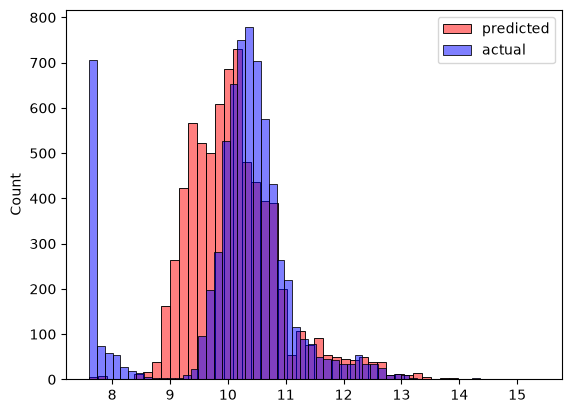

In [130]:
# To see how good the predictions are, let's plot them as a histogram and compare with the histogram of the actual target values.
sns.histplot(y_pred, color="red", alpha=0.5, bins=50, label="predicted")
sns.histplot(y_train, color="blue", alpha=0.5, bins=50, label="actual")
plt.legend()

Looking at the chart, the distribution of predictions does not really match the distribution of actual values.

Just by looking at this chart we suspect **the model is not ideal, but that is not an objective way to say it**.  
And when we start improving the model, we want to be sure that it indeed improved.  
For that **we need a single number that quantifies how good or bad the model is**.  
That is exactly what we will do in the next section with **RMSE**.

## 9. RMSE (Root Mean Squared Error)

RMSE (Root Mean Squared Error): one way of quantifying how good or bad a regression model is.

### The formula

RMSE starts from the difference between the prediction and the actual value.  
For each observation $i$, $g(x_i)$ is the prediction we make and $y_i$ is the actual value.  
We take the difference, square it, average these squared differences over all $m$ observations, and finally take the square root:

$$RMSE = \sqrt{ \frac{1}{m} \sum_{i=1}^{m} (g(x_i) - y_i)^2 }$$

### Example

Imagine we have four observations. These are our predictions, and these are the actual prices:

```
y_pred:  10     9     11    10
y:        9     9     10.5  11.5
```

The first step is to take the difference between each prediction and the corresponding actual value:

```
10 - 9    =  1
 9 - 9    =  0
11 - 10.5 =  0.5
10 - 11.5 = -1.5
```

Next, we square each difference:

```
1   → 1
0   → 0
0.5 → 0.25
-1.5 → 2.25
```

Squaring does two things: it makes negative and positive errors comparable, otherwise they would cancel each other out, and it penalizes larger errors more.

Then we take the average of the squared errors:

```
(1 + 0 + 0.25 + 2.25) / 4 = 0.875
```

This is the mean squared error, MSE. For our example, the mean squared error is 0.875:

The last step is the square root:

sqrt(0.875) ≈ 0.93

The square root brings the error back to the same units as the target variable. For these four observations, 0.93 is the root mean squared error.

### Implementation

In [131]:
# Now let's implement this in NumPy. The function takes the vector of actual values and the vector of predictions:
def rmse(y, y_pred):
    """
    y: vector of actual values
    y_pred: vector of predicted values
    """
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [132]:
# Now let's use it to evaluate our baseline model:
rmse(y_train, y_pred)

np.float64(0.7502216215431516)

The RMSE of the baseline model is about 0.76.  
This single number is much easier to work with than a chart.  
**Whenever we change something (add a feature, transform a variable, try a different model) we recompute it.**  
**If the number goes down, the model got better.**

So far we computed it on the training data. In the next section we apply the model to the validation set and see how it performs there.

## 10. Computing RMSE on Validation Data

In the previous section we implemented RMSE and used it to measure the quality of our baseline model.  
There was one problem: we measured it on the training data (the same data the model learned from).  
Here we fix that and evaluate the model the way it should be evaluated: on the validation data.

### The validation framework

We train the model, $g$, on the training dataset, and then we apply it to the validation part to see how it performs on data it has never seen.

![Validation Framework](https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/02-regression/images/10-car-price-validation-01-split-diagram-crisp.jpg)

### Preparing the feature matrix with prepare_X

In [133]:
# Let's take the code we wrote earlier. This is the code for training the model, and this line is where we prepare our feature matrix X:
X_train = df_train[base].fillna(0).values

# A lot of things are happening here, so let's write a special function for that. We'll call it prepare_X, and it takes a dataframe:
def prepare_X(df):
    """
    df: dataframe with the features
    """
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

The function does three things:
- First it selects the numerical columns
- then it fills the missing values
- and finally it extracts the feature matrix (the NumPy array) and returns it.  

We went from one line to five, but it is easier to understand what is going on.

The point of this function is that we prepare the data in the same way regardless of whether it is the training, validation or test dataset.  
It works on any dataframe (that is why the argument is just `df` and not `df_train`).

### Computing the RMSE on Validation data

Now we can train the model and validate it.

In [134]:
# First the training part: we prepare the matrix from the training dataframe and train the model.
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

# Then the validation part: 
# we prepare the validation matrix with the same function,
X_val = prepare_X(df_val)
# apply the model,
y_pred = w0 + X_val.dot(w)
# and compute the RMSE between the actual target values and our predictions
rmse(y_val, y_pred)

np.float64(0.7469867110519196)

The number is pretty similar to what we had on the training data. That is what we want to see: the model behaves on unseen data about as well as on the data it learned from.

Looking at the code, we can see the two parts clearly:
- The training part only touches the training dataset: we prepare the matrix and learn the weights.
- The validation part prepares the validation dataset in the same way as the training dataset, then applies the model learned in the previous step, and computes the root mean squared error for that model.

Now we have a way of evaluating the quality of our model using the root mean squared error on the validation dataset.  
This also means we can check whether a change actually improves the model. And this is what we will do next, starting with feature engineering.

## 11. Feature Engineering

**Feature engineering** is the process of **creating new features from the ones we already have.** 

In this section we create our first new feature, the age of a car, and see it improve the RMSE of our model quite a bit.

### From year to age

One of the columns in our dataset is `year`, and we know this is one of the most important variables for predicting the price of a car: if a car is old, it is usually cheaper, and if it is new, it is more expensive.

Instead of using the year as it is, we can compute the age of a car.  
For that we need to know when this data was collected. It turns out it was collected in 2017. So "now" is 2017, and the age is simply `2017 - year`. Some of the cars are 0 years old, some are 9, some are 26:

```
2017 - df_train.year
```

This age is what we want to use as a feature in our model.

### Adding the age feature to prepare_X

Let's modify the `prepare_X` function we wrote in the previous section.  
The new feature is called `age`, and we compute it in the same way we just did, except that instead of `df_train` we use the dataframe the function receives: it could be the training, validation or test set.

We also need to use the new feature when building the matrix. Instead of `base`, we create a list called `features` that contains the baseline numerical features plus the new `age` feature:

In [137]:
def prepare_X(df):
    df['age'] = 2017 - df.year
    features = base + ['age']

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    
    return X

### The function should not modify the data

When we run this function, the first line adds a new column, and if we look at `df_train` again, we see that a new column appeared in it. We modified the dataframe we passed in.

This is not something this function should do. As a user of this function, I don't want it to change my data. What if it does something that cannot be undone? **It is much better if the function doesn't modify the dataframes it receives.**

**The fix** is simple: **before doing anything, we take a copy of the dataframe and work with that copy inside the function. The original dataframe stays unchanged.**  
**After the function returns, we simply forget about the copy, because all we care about at the end is `X`.**

In [138]:
def prepare_X(df):
    df = df.copy()

    df['age'] = 2017 - df.year
    features = base + ['age']

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    
    return X

Now `X_train` can have (we still have not run the function yet) six columns: the five base features plus age, which is the last one.

### Checking the improvement

Let's validate the model with the same code as before: prepare the matrices, train the model, apply it to the validation set and compute the RMSE:

In [139]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5202024653795039)

The model improved, and it is quite an improvement: the RMSE went down from 0.75 to 0.52.

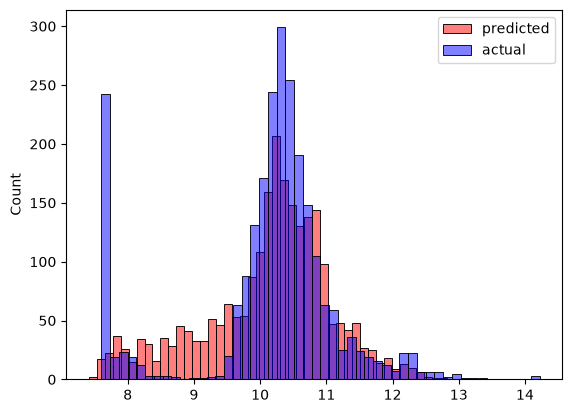

In [140]:
# We can see that it is a big improvement by doing the same thing as previously: 
# plotting the predicted values and the actual values on the same histogram. 
# Note that now we compare against y_val, because we are predicting on the validation dataset, not on the training dataset as previously.
sns.histplot(y_pred, color="red", alpha=0.5, bins=50, label="predicted")
sns.histplot(y_val, color="blue", alpha=0.5, bins=50, label="actual")
plt.legend()

The shapes of the two distributions are now much closer.  
There is still a lot of room for improvement, for example, the model completely misses this bar here, but in general it is doing much better.

We can add even more features. In the next section we will talk about categorical variables: columns like `model`, `make` and so on.

## 12. Categorical variables

**Categorical variables** are **variables that contain categories instead of numbers**.  
In this section we add them to our car price model and see that one of them breaks it completely, which is exactly the problem the next section solves.

### Variables that are categories

So far we only used numerical features. But the dataset has quite a few categorical variables. They are typically strings: `make`, `model`, `engine_fuel_type`, `transmission_type`, `driven_wheels` and others. If we look at the data types, all the columns of type `str` are categorical variables.

There is one variable that looks numerical but is not: `number_of_doors`. It contains 2, 3 and 4 (numbers) but these numbers are distinct categories of cars: cars with two doors, cars with three doors and cars with four doors are quite different. It just happened that the values of this variable are numbers, and that's why pandas treats them as usual numbers.

We want to use variables like that in our model, because they could be important. For example, cars with two doors are probably more expensive than cars with four doors.

### Encoding categories as binary columns

**ML models can only work with numbers, so we need to encode categorical variables**.  
**The typical way of doing it: for each value of the column, we create a separate binary column.**  
If our column contains the values 2, 3, 4 and 2 again, we represent it with three columns (one for each door count) and put 1 in the column that matches the row, and 0 everywhere else:

| number_of_doors | num_doors_2 | num_doors_3 | num_doors_4 |
| --- | ---: | ---: | ---: |
| 2 | 1 | 0 | 0 |
| 3 | 0 | 1 | 0 |
| 4 | 0 | 0 | 1 |
| 2 | 1 | 0 | 0 |

One categorical column becomes multiple binary columns, and each row gets exactly one 1.

In pandas, the comparison operator does most of the work. When we say `df.number_of_doors == 2`, we get `True` for every car that has two doors:

```python
df_train.number_of_doors == 2
```

The result is a series of booleans, so the only thing left is to turn it into integers (ones and zeros) with `astype(int)`.

To create the columns, we can write a loop over the values `[2, 3, 4]` and use a string template for the name, so that each value gets its own column:

```python
for v in [2, 3, 4]:
    df_train['num_doors_%s' % v] = (df_train.number_of_doors == v).astype('int')
```

### Adding doors to prepare_X

Let's modify our `prepare_X` function again.  
We make a copy of the dataframe as before, because we don't want to accidentally write these columns into our data.  
We also make a copy of the `base` list: if we used `append` on base itself, we would append `age` to it every time the function runs.

In [141]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype(int)
        features.append('num_doors_%s' % v)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    
    return X

In [142]:
# Now the features list can contain the baseline features, then age, and then the three new features: num_doors_2, num_doors_3 and num_doors_4.
# We validate the model with the same code as before:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5163192283176334)

The previous result was 0.520 and now we get 0.516.  
It improved only slightly. The improvement is almost negligible.  
The number of doors feature is not that useful.

### Adding the make

In [150]:
# If we look at the values of the make column, there are a lot of them (48 unique makes). 
df.make.unique()

<StringArray>
[          'bmw',          'audi',          'fiat', 'mercedes-benz',
      'chrysler',        'nissan',         'volvo',         'mazda',
    'mitsubishi',       'ferrari',    'alfa_romeo',        'toyota',
       'mclaren',       'maybach',       'pontiac',       'porsche',
          'saab',           'gmc',       'hyundai',      'plymouth',
         'honda',    'oldsmobile',        'suzuki',          'ford',
      'cadillac',           'kia',       'bentley',     'chevrolet',
         'dodge',   'lamborghini',       'lincoln',        'subaru',
    'volkswagen',        'spyker',         'buick',         'acura',
   'rolls-royce',      'maserati',         'lexus',  'aston_martin',
    'land_rover',         'lotus',      'infiniti',         'scion',
       'genesis',        'hummer',         'tesla',       'bugatti']
Length: 48, dtype: str

In [151]:
# We can take the most popular ones with value_counts:
df.make.value_counts().head()

make
chevrolet     1123
ford           881
volkswagen     809
toyota         746
dodge          626
Name: count, dtype: int64

In [148]:
# The output shows the counts, and the names themselves are in the index, so we wrap it in a list:
makes = list(df.make.value_counts().head().index)
makes

['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']

In [153]:
# This gives us the five most popular makes of cars: chevrolet, ford, volkswagen, toyota, and dodge.
# We can include them in the same way as the number of doors: one binary column per make
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype(int)
        features.append('num_doors_%s' % v)

    for v in makes:
        df['make_%s' % v] = (df.make == v).astype(int)
        features.append('make_%s' % v)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    
    return X

# We validate again
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)
X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5083161057006566)

This time the results improve by about one percent: 0.508 instead of 0.516. Not as drastic as when we added age, but quite okay.

### Doing the same for all categorical variables

We can do the same for the other categorical variables: `engine_fuel_type`, `transmission_type`, `driven_wheels`, `market_category`, `vehicle_size` and `vehicle_style`. I'm not adding `model` here because there are simply too many models.

In [154]:
# First we collect the top five most common values for each of them into a dictionary:
categorical_variables = [
    'make', 'engine_fuel_type', 'transmission_type', 'driven_wheels',
    'market_category', 'vehicle_size', 'vehicle_style'
]

categories = {}

for c in categorical_variables:
    categories[c] = list(df[c].value_counts().head().index)

In [155]:
# Then we take prepare_X and thrown in all the categories.
# We need 2 loops: one over the key-value pairs of the dictionary, and inside it another loop over the values of each category.
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype(int)
        features.append('num_doors_%s' % v)

    for c, values in categories.items():
        for v in values:
            df['%s_%s' % (c, v)] = (df[c] == v).astype(int)
            features.append('%s_%s' % (c, v))

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    
    return X

### Something went wrong

In [156]:
# We execute the same validation code again
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)
X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(817.5735242728105)

In [157]:
w0, w

(np.float64(2.6640437956976908e+16),
 array([ 2.67444011e+00, -1.11408077e+02, -9.31091530e+00,  5.17178061e+01,
         1.24715966e-02,  2.23889157e+01, -2.93481127e+04, -2.92849404e+04,
        -2.93446087e+04,  4.69852532e+01,  7.17535315e+00,  9.30982739e+01,
        -7.59362327e+01,  6.40562437e+01, -9.94493418e+02, -9.47696173e+02,
        -9.24540946e+02, -8.93095531e+02, -1.05006680e+03,  1.03436165e+17,
         1.03436165e+17,  1.03436165e+17,  1.03436165e+17,  1.03436165e+17,
        -1.30076603e+17, -1.30076603e+17, -1.30076603e+17, -1.30076603e+17,
         4.23319729e+01, -1.69066806e+01, -2.17845666e+01, -4.45382331e+01,
         5.56313393e+01,  1.08165911e+02,  1.44889941e+02,  1.56521366e+02,
         4.11331202e-02,  7.58086734e-02,  2.55284682e-01,  3.56234076e-01,
        -1.15776007e-01]))

Now the value is significantly higher than what we had before.  
Something went wrong. If we look at the weights that our train_linear_regression function outputs, they are huge: some of them are around 10 to the power of 17. We wanted to improve our model by adding more variables, but we just made it worse.

In the next section we will see why that happened and how to fix it.

## 13. Regularization

In the previous section we added categorical variables to our model and ended up with a **big RMSE and huge weights**.  
In this section we look at **why that happened** and learn a **technique for dealing with it: regularization**.

### The inverse that doesn't always exist

Remember the formula for the normal equation we use for training our model:

```
w = (XᵀX)⁻¹ Xᵀ y
```

**The problem we have is with this part: we need to take the inverse of the Gram matrix `XᵀX`, and sometimes this inverse doesn't exist.**

**It usually happens when the feature matrix `X` has duplicate columns**. Let's quickly check it with a small matrix where the second and the third columns have the same values:

```
X = [
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5],
]
```

W**hen we compute the Gram matrix, we see that it also has duplicate columns**: the second and the third are the same.

**When something like that happens, the inverse simply doesn't exist**. In linear algebra they say that one column is a linear combination of the other columns, which here just means that the third column is a duplicate of the second one.

Small parenthesis about linear combination: one column is a linear combination of others when you can express one column of a matrix as a sum of others columns. E.g. we have 3 columns: `a`, `b`, `c`. If `c = 0.2 * a + 0.5 * b`, then `c` is a linear combination of `a` and `b`.

In [164]:
X = [
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5],
]

X = np.array(X)

XTX = X.T.dot(X)
XTX

array([[140, 111, 111],
       [111, 108, 108],
       [111, 108, 108]])

Given that X had the 2nd and 3rd columns similar, the resulting Gram matrix XTX also has similar 2nd and 3rc columns.  
We said that it cannot have an inverse. Let's see:

In [165]:
XTX_inv = np.linalg.inv(XTX)
XTX_inv

LinAlgError: Singular matrix

And effectively, it does not have an inverse.  

### Noisy data makes the inverse huge

The duplicate columns is not exactly the case for our car price problem: there we did not see the singular  matrix error (see the output of the errorwe just had).  
The reason is that real data is usually not super clean. When people record observations, they make mistakes: instead of writing 5, they write 5.00000001.

In [168]:
# Let's add a tiny number like that to one value in our matrix:
X = [
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5.0000000001],
]
X = np.array(X)
# Now the columns are no longer exactly the same (they are slightly different) so the matrix is not exactly singular anymore.
# It should become numerically invertible, and we should be able to compute the inverse without an error.
XTX = X.T.dot(X)
XTX_inv = np.linalg.inv(XTX)
XTX_inv

array([[ 3.85852104e-02, -3.09242857e+02,  3.09207143e+02],
       [-3.09250483e+02,  7.03687442e+13, -7.03687442e+13],
       [ 3.09210826e+02, -7.03687442e+13,  7.03687442e+13]])

But look at what it comes up with: the numbers in the inverse are huge, around 10 to the power of 13.  
When we use this inverse to compute the weights, the weights for the duplicated features turn out to be very large numbers too.

In [169]:
y= [1, 2, 3, 1, 2, 3]
XTX_inv.dot(X.T).dot(y)

array([ 5.17914730e-01, -8.82187500e+03,  8.82178906e+03])

The weight for the unique first feature is fine (0.52), but for the second and third features we get something like -8.8 thousand and 8.8 thousand.

**So whenever we have duplicates (or near-duplicates) in our feature matrix, we get this problem.**

### A smaller example

In [170]:
XTX = [
    [1, 2, 2],
    [2, 1, 1],
    [2, 1, 1]
]

XTX = np.array(XTX)
XTX_inv = np.linalg.inv(XTX)

LinAlgError: Singular matrix

In [172]:
XTX = [
    [1, 2, 2],
    [2, 1, 1.0000001],
    [2, 1.0000001, 1],
]
XTX = np.array(XTX)
XTX_inv = np.linalg.inv(XTX)
XTX_inv

array([[-3.33333356e-01,  3.33333339e-01,  3.33333339e-01],
       [ 3.33333339e-01, -5.00000008e+06,  4.99999991e+06],
       [ 3.33333339e-01,  4.99999991e+06, -5.00000008e+06]])

### Controlling the weights with regularization

**To solve this problem, we can add a small number to the diagonal of the matrix.**  
**If we add a small number to the diagonal, say 0.01, the inverse can still be found, and the numbers in it are much more under control.**  
**The larger the number we add to the diagonal, the more control we get over the weights.**

**This works because by adding something to the diagonal, we make sure that it is less possible that one column is a duplicate of another.**

To add a number to the diagonal, we use the identity matrix, `np.eye(3)` is the 3×3 identity matrix, which has ones on the diagonal. When we add it to our matrix, the diagonal increases by one:

```python
XTX + np.eye(3)
```

**To add only a small number, we multiply the identity matrix by that number first:**

```python
XTX = XTX + 0.01 * np.eye(3)
```

**This way of controlling the weights is called regularization.**

**The number we add is actually a parameter. The larger the number on the diagonal, the smaller the values in the inverse of `XᵀX`. How much regularization to add becomes a parameter of our model.**

### The regularized training function

In [173]:
# we can go back to our function for training linear regression and slightly change it. 
# We'll call it train_linear_regression_reg, and it gets one more parameter "r" short for regularization
# Everything stays the same except one line: after computing the Gram matrix, we add r to the main diagonal.
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    # we add r to the diagonal of the Gram matrix
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [174]:
# Let's take the code from the previous section and replace the training function with this new one, using r=0.01:
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r=0.01)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.4542214062010737)

The result is not only much better than the 817 we got with the non-regularized version, it is also better than what we had before adding all the categorical variables.

By adding a number to the diagonal we were able to control our weights and regularize the model. But r is a parameter: if we set it too high, the model becomes worse, and if we set it to 0, we are back to the usual linear regression.  
So now we need to find the best value for r, and this is what we will do in the next section.

Small parenthesis about the regularization technique we used: adding a factor to the diagonals of Gram Matrix is Ridge Regression or Tikhonov regularization. See [https://en.wikipedia.org/wiki/Ridge_regression](https://en.wikipedia.org/wiki/Ridge_regression).

## 14. Tuning the model

**Tuning the model means finding the best value for the regularization parameter `r`, and the validation set is exactly the tool for that.**

### Trying different values of r

In [175]:
# What we will do is simply try a bunch of different values for r: 
# starting from zero, then something small, gradually increasing it, and maybe even 10:
for r in [0, 0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, score)

0 2.6640437956976908e+16 817.5735242728105
1e-05 5.520036690253746 0.45414517670888055
0.0001 6.537106285692221 0.45414585658228585
0.001 6.537785449792899 0.4541526823467233
0.01 6.513116347067104 0.4542214062010737
0.1 6.304029931077871 0.45492616130871333
1 5.463653660339291 0.4597501048794231
10 4.150525510759646 0.47906208950259005


### Reading the results

What we see: for zero regularization the bias term is huge and the RMSE is huge too. That is the broken model with the duplicated columns problem. But for even a little bit of regularization it improves immediately, and after that the score doesn't really change that much. It starts to become a bit worse as we increase the regularization, and when it's 10 it's even worse.

Looking at the bias term, the more regularization we add, the smaller it is. It looks like maybe 0.001 is a good value, because the model hasn't started to degrade in performance there, and it's not too large. To be honest, it doesn't really matter here, it could be this one or the one next to it. We can just go with 0.001.

### Training the final model

In [176]:
# Let's train our model once again with the selected value:
r = 0.001
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r=r)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
score = rmse(y_val, y_pred)
score

np.float64(0.4541526823467233)

We selected the best regularization parameter, trained the model with it, and we saw that it works on the validation set.  
Now what we need to do is check it on the test dataset as well, and this is what we will do in the next section.

## 15. Using the model

In the previous section we found the best regularization parameter.  
In this section we train the final model, check it on the test data, and then use it the way it would be used in practice: to predict the price of a single car.

### Training the final model

Remember that we split our dataset into three parts: train, validation and test.  
So far we trained the model on the training part and computed the RMSE on the validation part.  
For the final model we do something different: we combine the training and validation datasets into one `full_train`, train the model on all of it, and then make the final evaluation on the test dataset.

The idea is simple: now that we have tuned all the parameters, we want to give the model as much data as possible for training, and keep the test set untouched for the final check.  
The RMSE on test shouldn't be too different from what we saw on validation.

We have two dataframes, `df_train` and `df_val`, and we want to combine them into one. In pandas there is a function for that, `concat`, short for concatenate. It takes a list of dataframes and concatenates them together:

In [177]:
df_full_train = pd.concat([df_train, df_val])
df_full_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,cadillac,cts,2015,premium_unleaded_(recommended),272.0,4.0,automatic,rear_wheel_drive,4.0,"luxury,performance",large,sedan,30,20,1624
1,mercedes-benz,cl-class,2013,premium_unleaded_(required),429.0,8.0,automatic,all_wheel_drive,2.0,"luxury,high-performance",large,coupe,24,15,617
2,mazda,cx-9,2015,regular_unleaded,273.0,6.0,automatic,front_wheel_drive,4.0,crossover,large,4dr_suv,24,17,586
3,land_rover,discovery_series_ii,2001,premium_unleaded_(required),188.0,8.0,automatic,four_wheel_drive,4.0,luxury,midsize,4dr_suv,16,12,258
4,toyota,avalon,2017,regular_unleaded,268.0,6.0,automatic,front_wheel_drive,4.0,NaN,midsize,sedan,30,21,2031
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2377,volkswagen,new_beetle,2008,regular_unleaded,150.0,5.0,automatic,front_wheel_drive,2.0,NaN,compact,convertible,28,20,873
2378,ford,f-150,2017,regular_unleaded,325.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,23,18,5657
2379,pontiac,g6,2008,regular_unleaded,252.0,6.0,automatic,front_wheel_drive,4.0,performance,midsize,sedan,26,17,210
2380,buick,regal,2016,premium_unleaded_(recommended),259.0,4.0,automatic,front_wheel_drive,4.0,performance,midsize,sedan,30,21,155


If we look at the result, we see that even though there are around 9500 rows now, the index still contains the values from the validation dataframe. We can fix that by resetting the index:

In [178]:
df_full_train = df_full_train.reset_index(drop=True)
df_full_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,cadillac,cts,2015,premium_unleaded_(recommended),272.0,4.0,automatic,rear_wheel_drive,4.0,"luxury,performance",large,sedan,30,20,1624
1,mercedes-benz,cl-class,2013,premium_unleaded_(required),429.0,8.0,automatic,all_wheel_drive,2.0,"luxury,high-performance",large,coupe,24,15,617
2,mazda,cx-9,2015,regular_unleaded,273.0,6.0,automatic,front_wheel_drive,4.0,crossover,large,4dr_suv,24,17,586
3,land_rover,discovery_series_ii,2001,premium_unleaded_(required),188.0,8.0,automatic,four_wheel_drive,4.0,luxury,midsize,4dr_suv,16,12,258
4,toyota,avalon,2017,regular_unleaded,268.0,6.0,automatic,front_wheel_drive,4.0,NaN,midsize,sedan,30,21,2031
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9527,volkswagen,new_beetle,2008,regular_unleaded,150.0,5.0,automatic,front_wheel_drive,2.0,NaN,compact,convertible,28,20,873
9528,ford,f-150,2017,regular_unleaded,325.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,23,18,5657
9529,pontiac,g6,2008,regular_unleaded,252.0,6.0,automatic,front_wheel_drive,4.0,performance,midsize,sedan,26,17,210
9530,buick,regal,2016,premium_unleaded_(recommended),259.0,4.0,automatic,front_wheel_drive,4.0,performance,midsize,sedan,30,21,155


Now everything is sequential, and we can use the `prepare_X` function to get the feature matrix:

In [179]:
X_full_train = prepare_X(df_full_train)

We also need the target values `y`. There is a function in NumPy called `concatenate` that does the same thing for arrays, and since arrays have no index, we don't need to reset anything:

In [180]:
y_full_train = np.concatenate([y_train, y_val])

Now we take the code for training the model and replace `X_train` with `X_full_train`, `y_train` with `y_full_train`, and use the `r` we selected earlier:

In [182]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)
w0, w

(np.float64(6.799574020003844),
 array([ 1.37646847e-03,  1.09614945e-01, -3.57336014e-02,  1.40325765e-02,
        -4.68692887e-05, -1.01136559e-01, -1.11760420e+00, -1.31818613e+00,
        -1.00285008e+00, -1.43938117e-02,  1.66774149e-01,  5.73602290e-03,
        -1.29338727e-01, -7.91526686e-02, -4.90604333e-01,  6.49560284e-02,
        -3.32100560e-01, -5.65481453e-01,  2.40780628e-02,  1.17221698e+00,
         9.88869055e-01,  1.22443058e+00,  2.85049988e+00,  5.61310181e-01,
         1.79510705e+00,  1.63991909e+00,  1.74289679e+00,  1.62152467e+00,
        -8.86721794e-02,  3.42070874e-02, -3.92157746e-02, -2.49826790e-02,
         1.63686952e-02,  2.34880154e+00,  2.23197440e+00,  2.21846598e+00,
         3.74030162e-02,  5.92110641e-02,  2.35465689e-01,  3.48223560e-01,
        -1.09525553e-01]))

This is our final model, and these are its weights.

### Checking the model on test data



In [183]:
# To check the final model, we prepare the test dataset exactly in the same way as we did the validation dataset,
# we just replace validation with test:
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
score

np.float64(0.5146188369637252)

The RMSE is close to the one on validation.  
That is a very good sign. It means our model generalizes well: it didn't get this score just by chance.

### Predicting the price of a car

Now we can use the model the way we actually want to use it: to predict the price of a car.  
Imagine there is a car, we extract all its features, put the feature vector into the model, and it tells us the price.

For that we can take any car from the test dataset and pretend it's a new car.  
This is fine, because we didn't train our model on this data.  
Let's take a Toyota Sienna:

In [189]:
car = df_test.iloc[2336].to_dict()
car

{'make': 'toyota',
 'model': 'sienna',
 'year': 2015,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 266.0,
 'engine_cylinders': 6.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'front_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'large',
 'vehicle_style': 'passenger_minivan',
 'highway_mpg': 25,
 'city_mpg': 18,
 'popularity': 2031}

Usually we don't get a dataframe when we want to make a prediction.  
In a real life scenario it could be a website or an app where people enter the values about the car, and the website sends a request with all this information to the model. The model replies back with the price.  
That's why we turn the car into a dictionary: this is how such requests usually look.

Our `prepare_X` function expects a dataframe, though. So we create a small dataframe with a single row. Pandas can create a dataframe from a list of dictionaries, and our list contains just the one car from the request:

In [192]:
df_small = pd.DataFrame([car])
X_small = prepare_X(df_small)

# Then we apply the model to this feature matrix with 1 row:
y_pred = w0 + X_small.dot(w)
y_pred = y_pred[0]
y_pred

np.float64(10.448182869730687)

Remember: this is the logarithm of the price, not the price itself. To undo the logarithm, we take the exponent:

In [193]:
np.expm1(y_pred)

np.float64(34480.66007794328)

This is our prediction: we think that a car with these characteristics should cost 34,480.
Let's see how much this car actually costs:

In [194]:
np.expm1(y_test[2336])

np.float64(38455.00000000001)

So our prediction was a bit off. The car costs $38,455 and we predicted $34,480. It's not perfect, but it's a relatively good prediction.

So this is how we can first train a full model, and then apply this model to predict the price of a single car.

## 16. Car price prediction project Summary

### The project

We downloaded a dataset of cars that had prices and different characteristics, things like make, model, engine fuel type, transmission type and others.  
The target variable we wanted to predict was the price, MSRP, which stands for manufacturer's suggested retail price.

### Data Preparation and EDA

First we cleaned the dataset and prepared it, so it looks more uniform.  
The column names had spaces and inconsistent capitalization, and the string values did too, so we made everything lowercase with underscores.  
Now it looks cleaner.

Then we did Exploratory Data Analysis.  
We identified that the distribution of price has a long tail, and we removed the long tail by applying the logarithmic transformation.  
That's a good idea, because when a distribution has a long tail, machine learning models usually have problems with it.  
After the transformation it looks like a bell shaped curve.

We also saw that the dataset has missing values, and with missing data we cannot really train a model, so we need to do something about it.  
We decided to simply replace them with zeros.

### The validation framework

Then we set up the validation framework: we split the data into training, validation and test parts. This turned out to be one of the most useful things we did. It let us detect problems with the model early.

### Linear regression and the normal equation

Next we looked at how linear regression works. First for a single example, implemented as a simple formula with a for loop. Then we extended it to the vector form using the dot product, and finally to the matrix form (a matrix vector multiplication). The output of linear regression is the weights vector: the bias term and the weights.

And then we looked at how to actually obtain these weights (how to train the model). We saw that machine learning is not magic: it's just a formula, and this formula is called the normal equation. We implemented it in NumPy, and with this implementation we trained our first model, the baseline model, which used only the five base numerical features.

The baseline model didn't do really well, as we saw in the graph. But judging from a graph alone is not an objective way to measure the performance of a model. That's why we talked about RMSE, the root mean squared error, a metric for evaluating the quality of regression models.

The `prepare_X` function we wrote gave us the same way of preparing the feature matrix for the training and the validation datasets. That allowed us to experiment a lot faster: throughout the session we just kept redefining this function and copy-pasting the same validation cell.

### Feature engineering and categorical variables

After that we did simple feature engineering: creating new features from existing ones. We created the age feature, and it improved the performance of our model drastically: the distribution of predictions started to match the distribution of actual values much better than previously.

Then we looked at how to integrate categorical variables. We represented each categorical variable with a bunch of binary columns. This way of encoding categorical variables is called one-hot encoding, and we will talk about it in more details in the next chapter, when we talk about classification.

After adding all the categorical features we found out that the performance of our model degraded significantly: all of a sudden the RMSE became very huge. Luckily we had the validation framework, so we could spot the problem easily. The reason was numerical instability, and as a way to solve it we used regularization: we added a small number to the diagonal of the matrix X transpose X before inverting it. That helped, and the performance of the model with all the categorical features increased quite a lot compared to the previous version.

To summarize the whole project in one list:
- EDA - looking at data, finding missing values
- Target variable distribution - long tail, so we applied the log transformation
- Validation framework: train/validation/test split - it helped us detect problems
- Normal equation - not magic, but math
- Implemented it with NumPy
- RMSE to validate our model
- Feature engineering: age, categorical features
- Regularization to fight numerical instability

### Tuning and the final model

After regularization we tried different values of the regularization parameter to find the best one. We concluded that 0.001 seems like a good choice. Maybe it's not the absolute best, but it's on the same level as the others, so we decided to go with it.

Then we trained our final model: we combined the training and validation datasets into one full train dataset, used our `prepare_X` function again and trained the model. We also saw how to apply this model to a car for which we don't know the price. Well, actually we do know it, because the car came from the test dataset, but we pretended we don't, and the prediction we got wasn't far off from the actual price.

<style>
/* 1. Forces wide tables and standard HTML outputs to fit */
.output_subarea, .output_html, table.dataframe {
    max-width: 100% !important;
    overflow-x: auto !important;
    display: block !important;
}

/* 2. Forces standard stdout code prints, stderr outputs (like wget), 
      and Python Traceback errors to wrap text safely */
div.output_area pre, 
div.output_subarea.output_stream.output_stderr pre, 
div.output_subarea.output_error pre {
    white-space: pre-wrap !important;
    word-break: break-word !important;
}
</style>
